# 硫酸锌价格采集以及待处理的分析

这次我想把问题往前推一步：价格最后停在哪里，哪些变化值得拿去和供应商谈，哪些只是图上看起来热闹。

七水沿着原来的季度复盘往下走，原话保留。重复的“AI总结”放到最后，正文每一季后面接一张图和一段数据判断。一水补充分析放在后半部分，重点看报价的上下沿、供应商样本，以及含锌固废路线下到底该盯什么。

新增内容统一按附件里的“一水硫酸锌”分析。原文里的“一水硫酸铜”和其他原有措辞不改。

**数据截至2026年11月6日。** 11月是一水截至11月5日、七水截至11月3日的采价片段，12月缺失。2026年Q4只看10月和11月已有记录，不当成完整季度。

## 方法论

为什么是区间，不是一个准数 —— 免费公开数据里没有现成的三年月度价格表。生意社、百川、海关、企业年报、外贸平台，数据东一块西一块，规格和口径还不一样。所以就把每个月能搜到的报价都收进来，取个最低、最高，中间就是平均参考
- 数据来源 —— 生意社（七水基准价）、百川（成交均价）、海关（出口均价）、上市公司年报（宝海微元、埃索凯，拿来验证）、外贸平台 FOB 挂牌，还有论坛新闻公众号的报价。
- 价格口径 —— 价格分口径：挂牌价（报价，偏高）、成交价（实际成交，偏低）、基准价（中间参考）。同一时期，百川的成交价比生意社基准价能低个 600 块左右。所以比价前先搞清楚对方报的是哪一种，别拿挂牌价去比成交价。
- 采价逻辑 —— 它是「锌含量 + 硫酸 + 加工费 + 运费」加出来的。锌价只是影响成本的一个方向，不能拿锌价涨跌直接推硫酸锌。

### 这几张表能告诉我什么

先把“平均价”这个名字说清楚：表里基本是最低、最高报价的中点，个别地方取了整。后面统一叫**参考中点**，它没有成交量权重，也不是所有供应商的平均成交价。

一水是混规格企业挂牌，七水2025年5月以后主要换成了生意社单点基准。低价、高价可能来自不同厂家和不同规格。所以区间是采到的报价带，不是成交价格的分布，更不是置信区间。一个月上下沿相同，只能说明表里留了一个点。

XLSX与两份月度CSV逐月核对一致，不合并成两倍样本。后面的数字都来自这些附件。原文里的停产、TC、开工率、硫酸价格等解释原样保留，属于原有判断；这几张价格表本身没有对应变量，不能用来证明原因，也不能算出多空因素的权重。

In [1]:
import io
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = ["PingFang SC", "Hiragino Sans GB", "Microsoft YaHei", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 115
plt.rcParams["axes.titlesize"] = 12
pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 120)

DATA_DIR = None

In [2]:
原始CSV = {'一水硫酸锌_月度区间.csv': '时间,最低价,最高价,平均价,来源备注\n2024-01,6500,8200,7350,企业挂牌：凯捷6500 · 佳业/森涛35.5% 7800-8200\n2024-02,6700,8200,7450,武汉恒久颗粒35% 6700 · 河南赛腾颗粒35% 8200（生意社2/16-17）\n2024-03,6500,8000,7250,凯捷6500 · 佳业35.5% 8000\n2024-04,7500,8200,7850,武汉恒久颗粒35% 7500 · 河南赛腾颗粒35% 8200（生意社4/1-3）\n2024-05,6500,8000,7250,凯捷6500 · 佳业35.5% 8000\n2024-06,5200,8200,6700,武汉恒久颗粒35% 7500→5200（月中回落）· 河南赛腾颗粒35% 8200（生意社6月）\n2024-07,6500,8000,7250,凯捷6500 · 佳业35.5% 8000\n2024-08,6300,8200,7250,日照一杰信元33.5% 6300 · 凯捷6500 · 森涛35.5% 7800-8200\n2024-09,5200,8200,6700,武汉恒久颗粒35% 5200 · 河南赛腾颗粒35% 8200（生意社9月）\n2024-10,6500,8000,7250,凯捷6500 · 佳业35.5% 8000 · 天悦工业98% 6500\n2024-11,6500,8000,7250,凯捷/天悦6500 · 佳业35.5% 8000\n2024-12,5200,8200,6700,武汉恒久颗粒35% 5200 · 河南赛腾颗粒35% 8200（生意社12月）\n2025-01,5200,8200,6700,武汉恒久颗粒35% 5200 · 河南赛腾颗粒35% 8200（生意社1月）\n2025-02,5200,8200,6700,武汉恒久颗粒35% 5200 · 河南赛腾颗粒35% 8200（生意社2月）\n2025-03,6500,7700,7100,天悦/凯捷6500 · 富盛永饲料级7700\n2025-04,6500,7800,7150,天悦/凯捷6500 · 富盛永7000 · 仟越星99% 7800\n2025-05,6500,8200,7350,凯捷6500 · 富盛永6900-6950 · 仟越星99% 7600-7700 · 森涛8200\n2025-06,4200,7700,5950,富盛永35.5% 4200 · 凯捷/天悦6500 · 仟越星99% 7700\n2025-07,4200,6500,5350,富盛永35.5% 4200 · 凯捷饲料级6500\n2025-08,4800,7500,6150,恒久颗粒35% 6700 · 天悦工业98% 6500 · 食品级4800 · 凯捷33% 7500（规格混杂）\n2025-09,4200,6500,5350,富盛永35.5% 4200 · 凯捷饲料级6500\n2025-10,4200,8500,6350,富盛永4200 · 佳业8500 · 仟越星99% 6900\n2025-11,6400,6800,6600,湖南锐启 农业级98%一水颗粒（阶梯价）\n2025-12,4200,8500,6350,多交易商混合规格\n2026-01,4200,8500,6350,富盛永4200 · 佳业8500 · 仟越星6900\n2026-02,4200,6900,5550,富盛永35.5% 4200/6200 · 仟越星99% 6900（永硕99% 14500特殊渠道，不计）\n2026-03,4800,7000,5900,恒久颗粒35% 5200 · 富盛永饲料级≥34.5% 7000 · 食品级4800\n2026-04,4800,7200,6000,富盛永4800 · 仟越星99% 7200\n2026-05,4800,8500,6650,富盛永4800 · 佳业8500 · 凯捷6500\n2026-06,4800,7200,6000,富盛永4800 · 凯捷6500 · 仟越星99% 7200\n2026-07,4800,7500,6150,恒久颗粒35% 6700 · 工业级97% 7000 · 食品级4800 · 凯捷33% 7500（规格混杂）\n2026-08,4800,8800,6800,富盛永4800 · 凯捷6500 · 仟越星99% 7500 · 佳业8800\n2026-09,6500,7400,6950,凯捷/天悦6500 · 仟越星99% 7400\n2026-10,4800,8800,6800,富盛永4800 · 凯捷6500 · 仟越星99% 7200 · 佳业8800\n2026-11,4800,8800,6800,富盛永35.5% 4800 · 凯捷/天悦6500 · 仟越星99% 7200 · 佳业35.5% 8800（生意社一水报价中心11/5）\n2026-12,,,,无免费数据\n', '七水硫酸锌_月度区间.csv': '时间,最低价,最高价,平均价,来源备注\n2024-01,3650,4500,4075,市场报价：百川盈孚1/9 七水96%≈3650、99%≈4500（河南凯捷7500未标规格，不计）\n2024-02,4350,5450,4900,市场报价：宝兴环保99% 4350 · 呈信宏丰97% 4550 · 佳业/凯捷4800 · 金昊99% 5450（生意社2/28商品报价动态）\n2024-03,4500,6415,5458,市场报价：晟远98% 4500 · 武汉恒久97.5% 6415\n2024-04,3600,7400,5500,市场报价：森美99% 3600 · 呈信宏丰97% 4550 · 滨州97.5% 6415 · 森涛99% 7400（生意社4/30）\n2024-05,4200,6415,5308,市场报价：滨州97.5% 6415（5/7、5/15、5/28）· 区间约4200\n2024-06,3600,4800,4200,市场报价：郑州多厂3600-4800 · 晟远98% 4500\n2024-07,3800,5950,4875,市场报价：宝兴99% 3800 · 滨州97.5% 4500 · 呈信宏丰97% 4550 · 金昊99% 5950（生意社7/19）\n2024-08,3900,5950,4925,市场报价：宝兴99% 3900 · 滨州97.5% 4500 · 呈信宏丰97% 4550 · 金昊99% 5950（生意社8/2）\n2024-09,4500,5500,5000,市场报价：晟远98% 4500 · 滨州97.5% 5500\n2024-10,4450,5500,4975,市场报价：多厂家 4450-5500\n2024-11,5300,5800,5550,市场报价：商品报价动态 5300-5800\n2024-12,5200,5500,5350,市场报价：滨州97.5% 5500 · 颗粒硫酸锌5200起（高至8200）\n2025-01,5000,5267,5134,月初~5267（全年高点）→1/15后回落至5000\n2025-02,4825,5000,4912,无单月基准（基准价系列2025-05才上线）；据滚动统计(2025-02-10起)该月落在4825-5000\n2025-03,4500,5300,4900,市场报价：湖北工业级4500 · 山东97%5000 · 江苏5200 · 河南21%出厂5300\n2025-04,4200,5500,4850,市场报价：97.5%≈5500、98%≈4200（山东滨州等）\n2025-05,5000,5000,5000,生意社七水基准（单点）\n2025-06,5000,5000,5000,生意社七水基准（单点）\n2025-07,5000,5000,5000,生意社七水基准（单点）\n2025-08,5000,5000,5000,生意社七水基准（单点）\n2025-09,5000,5000,5000,生意社七水基准（单点）\n2025-10,4850,5000,4925,月初5000→月末4850\n2025-11,4825,4825,4825,生意社七水基准（单点）\n2025-12,4825,4825,4825,生意社七水基准（单点）\n2026-01,4825,4825,4825,生意社七水基准 · 基准\n2026-02,4850,4850,4850,生意社七水基准 · 基准\n2026-03,4850,4850,4850,生意社七水基准 · 基准\n2026-04,4850,4850,4850,生意社七水基准 · 基准\n2026-05,4825,4825,4825,生意社七水基准 · 月初4850→月末4825\n2026-06,5125,5125,5125,生意社七水基准 · 月初4825→月末5125（6/22-26单周+6.22%）\n2026-07,5125,5125,5125,生意社七水基准 · 基准\n2026-08,5125,5125,5125,生意社七水基准 · 基准\n2026-09,5125,5125,5125,生意社七水基准 · 基准\n2026-10,4500,5800,5150,基准5125 + 市场报价4500-5800（主流5500）\n2026-11,5125,5125,5125,生意社七水基准 · 截至11/3\n2026-12,,,,无免费数据\n', '硫酸锌_出口与国际参考.csv': '项目,时间,价格,单位,来源\n中国海关出口均价 HS28332930,2023全年,0.861,美元/kg,"出口量90,408,806kg / 出口额77,812,315美元"\n中国海关出口额 HS28332930,2024全年,"176,135,233",美元,国贸通 / 海关总署\n中国海关出口均价,2024-12,0.876,美元/kg,"出口量24,960,916kg / 出口额21,856,854美元"\n中国海关出口额 HS28332930,2025全年,"227,534,506",美元,同比 +29.18%\n中国海关出口均价,2025-10,0.882,美元/kg,"出口量19,441,148kg / 出口额17,153,899美元"\n中国海关出口量,2026-07,"24,092,115",kg,海关总署\n中国海关出口量,2026-08,"20,921,550",kg,海关总署\n中国海关出口均价,2026-09,0.9351,美元/kg,涉及19个省市\n中国FOB挂牌 · 农业级一水,近期,400–500,美元/吨,made-in-china 等平台\n中国FOB挂牌 · 饲料级一水33-35%,近期,"950–1,200",美元/吨,同上\n中国FOB挂牌 · 七水农业级,近期,670–800,美元/吨,同上\n越南进口(自中国 · 饲料级一水),2024-04,820–830,美元/吨,报关价 HS28332940\n美国市场,2025 Q3–Q4,950–971,美元/吨,IMARC\n印度出口报价(七水),未标,520,美元/吨,Suraj Fine Chemicals\n全球均价(估),2025,720,美元/吨,行业报告\n'}

来源清单 = pd.DataFrame([{'文件': '一水硫酸锌_月度区间.csv', 'SHA256': '20c062e90fccb606754bcdb84711e7ac594ea4544288b4759316c6deb3bd8e61'}, {'文件': '七水硫酸锌_月度区间.csv', 'SHA256': '42619d49b2507e6baa5828475a3afd52a427a876ca604e0c8af90cfe62efa042'}, {'文件': '硫酸锌_出口与国际参考.csv', 'SHA256': '006b2b903f7131fc0cf53a874a1860c5e228e73496916a618bcdcef2b509726e'}, {'文件': '硫酸锌_月度价格区间_2024-2026.xlsx', 'SHA256': '2b91fa40f6b65bcbc3610ec032fc89070b3fc21a9e6e14e0015bae546250aa6b'}, {'文件': 'zinc sulfate 3 years analysis.ipynb', 'SHA256': 'df4c6604f61856c6cac55c1e8a38748a330fd11f4dc775d750e88328f4a1fc13'}])

def read_source(name):
    if DATA_DIR is not None:
        return pd.read_csv(Path(DATA_DIR) / name, encoding="utf-8-sig")
    return pd.read_csv(io.StringIO(原始CSV[name]))

ys_raw = read_source("一水硫酸锌_月度区间.csv")
qs_raw = read_source("七水硫酸锌_月度区间.csv")
exp = read_source("硫酸锌_出口与国际参考.csv")

In [3]:
def prepare(raw):
    df = raw.copy()
    df["日期"] = pd.to_datetime(df["时间"], format="%Y-%m")
    for col in ["最低价", "最高价", "平均价"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df = df.sort_values("日期").reset_index(drop=True)
    assert not df["时间"].duplicated().any(), "同月出现重复记录"
    valid = df.dropna(subset=["最低价", "最高价", "平均价"])
    assert (valid["最高价"] >= valid["最低价"]).all()
    assert (valid["平均价"].sub((valid["最低价"] + valid["最高价"]) / 2).abs() <= 0.5).all()
    df["年"] = df["日期"].dt.year
    df["月"] = df["日期"].dt.month
    df["季度"] = df["日期"].dt.to_period("Q").astype(str)
    df["参考中点"] = df["平均价"]
    df["报价带宽"] = df["最高价"] - df["最低价"]
    df["中点环比%"] = df["参考中点"].pct_change(fill_method=None) * 100
    return df

ys_all, qs_all = prepare(ys_raw), prepare(qs_raw)
ys = ys_all.dropna(subset=["参考中点"]).copy()
qs = qs_all.dropna(subset=["参考中点"]).copy()
qs["采价口径"] = np.select(
    [qs["来源备注"].str.contains("市场报价"), qs["来源备注"].str.contains("基准")],
    ["厂家混合报价", "基准或单点"], default="混合或滚动统计")

def coverage(df, name):
    return {"品种": name, "有值月份": df["参考中点"].count(),
            "起始": df["时间"].min(), "最后有值": df.loc[df["参考中点"].notna(), "时间"].max(),
            "缺失月份": "、".join(df.loc[df["参考中点"].isna(), "时间"])}

display(pd.DataFrame([coverage(ys_all, "一水"), coverage(qs_all, "七水")]))

,品种,有值月份,起始,最后有值,缺失月份
0,一水,35,2024-01,2026-11,2026-12
1,七水,35,2024-01,2026-11,2026-12


## 样本分析(七水）

先看价格走成什么样，再接季度解释。橙色是参考中点，浅色带是当月采到的最低和最高报价。2025年5月起口径有变化，跨过这条线时，不能把波动收窄全部解释成市场更稳定。

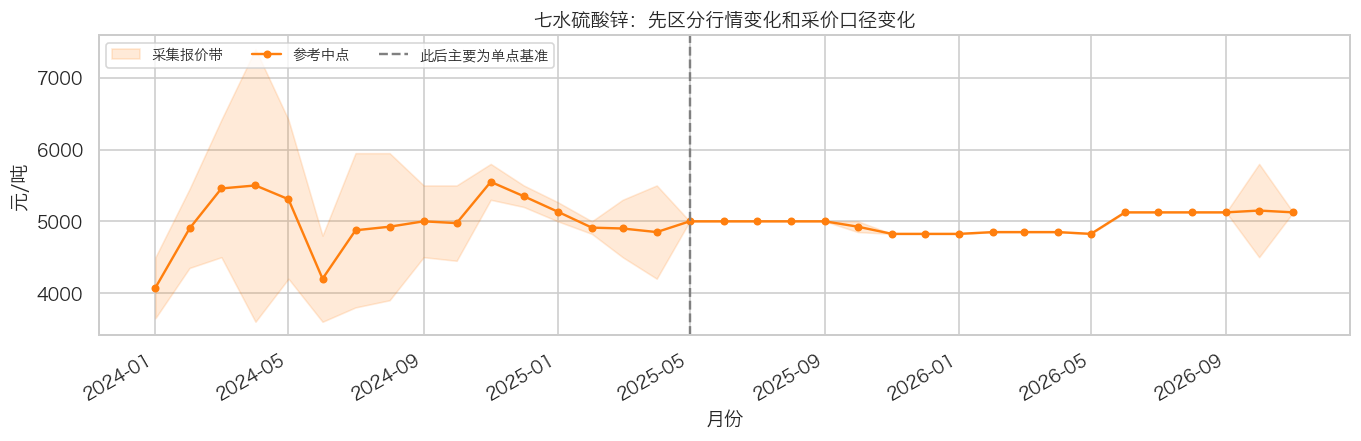

In [4]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(qs["日期"], qs["最低价"], qs["最高价"], color="tab:orange", alpha=.16, label="采集报价带")
ax.plot(qs["日期"], qs["参考中点"], marker="o", ms=4, color="tab:orange", label="参考中点")
ax.axvline(pd.Timestamp("2025-05-01"), color="gray", linestyle="--", label="此后主要为单点基准")
ax.set(title="七水硫酸锌：先区分行情变化和采价口径变化", ylabel="元/吨", xlabel="月份")
ax.legend(loc="upper left", ncol=3, fontsize=9)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

原图注及年度判断（原文保留）：

### 左上图月度价格趋势

#### 年度总结：

+ 2024年走出了比较夸张的波动，尤其是在2024年四月份的时候，但是在六月又直接从六千多暴跌到四千多每吨。
+ 2025和2026年高度平稳，属于正常震荡，这属于正常的市场博弈和决策惯性波动，维持在4800-5100元每吨

#### 分析(最明显的一点，就是四月份那个涨幅和暴跌）

为什么价格会暴涨？

对于大部分的硫酸锌制作，其实主要上游来源均为次氧化锌。在2024年受地方房地产收缩，钢厂的开工率下降，导致锌灰，氧化锌，次氧化锌的产量下降
次氧化锌的采购需求大量来自沿炼厂（mysteel），而化工只为次采购商，由于市场占有率略微没有主力竞争力，当供给收缩，计价指数就会自然而然的往上滚动，这是由于订单在短期内超过供给从而导致的短缺惯性

2024年四月在调查的15家钢厂有7厂停产，经过mysteel询问都是由于原料而影响，市场甚至出现0库存的紧俏局面

**对照数据再看：** 2024年4月报价带是3600—7400元/吨，中点5500；6月报价带是3600—4800，中点4200。同口径中点跌幅是23.6%。原话里的“六千多跌到四千多”保留，但图上要分开看报价上沿和中点。

2026年也不能统一概括成4800—5100：表里6月以后多数基准点是5125，10月混合报价中点5150。这里更适合说价格上了一个小台阶。

In [2]:
def quarter_plot(df, period, title, color="tab:orange"):
    """只画已有报价，不补齐缺失月，也不把同月不同报价当成连续成交。"""
    sub = df.loc[df["季度"].eq(period)].copy()
    fig, ax = plt.subplots(figsize=(8.5, 2.8))
    x = np.arange(len(sub))
    ax.vlines(x, sub["最低价"], sub["最高价"], color=color, alpha=.4, lw=8, label="采集报价带")
    ax.plot(x, sub["参考中点"], "o-", color=color, label="参考中点")
    for xi, v in zip(x, sub["参考中点"]):
        ax.annotate(f"{v:,.0f}", (xi, v), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9)
    ax.set_xticks(x, sub["时间"])
    ax.set(title=title, ylabel="元/吨", xlim=(-.4, len(sub)-.6))
    ax.margins(y=.2)
    # 基准只动几十元时留出至少600元纵轴跨度，避免视觉上放大小波动。
    bottom, top = ax.get_ylim()
    if top - bottom < 600:
        center = (bottom + top) / 2
        ax.set_ylim(center - 300, center + 300)
    ax.legend(fontsize=9, loc="best")
    plt.tight_layout()
    plt.show()

def quarter_stats(df):
    out = df.groupby(["年", "季度"], sort=True).agg(
        月份数=("参考中点", "size"), 季内中点均值=("参考中点", "mean"),
        首月中点=("参考中点", "first"), 末月中点=("参考中点", "last"),
        平均报价带宽=("报价带宽", "mean"))
    out["季内首末变化%"] = (out["末月中点"] / out["首月中点"] - 1) * 100
    return out

### 右上图为价格分布以及kde

### 分析
**2024第一季度：**
+ 七水的价格从4100元每吨启动，三月份加速到了5480元每吨，季末接近6000每吨
  + 春节之后矿段收紧（因素有减产，检修，环保等问题）举个例子：中国进口锌精矿加工费（tc）下降到八十美元每干吨，跌幅高达百分之70.（中信建投财报）境况加工费的快速下跌凸显出矿石的异常紧张
  + 国产锌精矿tc均价为4100元每吨，跌至2022年以来最低，这个价格低于4500元每吨的锌沿炼成本
  + 海外矿山主动减产 —— nystar，boliden
  + 价格触发减产，伦锌价格回调至2400美元每吨，触发亏损，从而连锁触发矿山的保护级别停产
  + 国内供给的季节性收缩，如天气，严寒，检修等
  + 需求端主动收紧 —— 冬季的节前备货，加上赶上采购窗口，价格只会往上去翻
  + 进口量同比下滑，一月份中国锌进口量为40万吨，环比减少百分之十，同比减少百分之九，1-2月降幅高达百分之三十



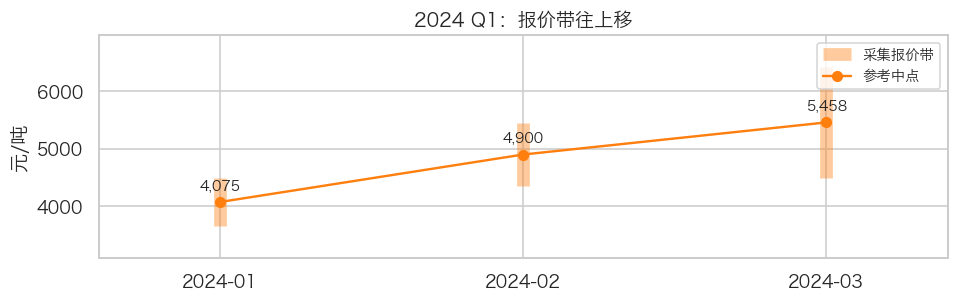

In [6]:
quarter_plot(qs, '2024Q1', '2024 Q1：报价带往上移')

**对照数据再看：** 1月到3月参考中点4075→5458，上升33.9%。这能支持“价格上来了”，但矿端、废料端、需求各出了多少力，不能从这三个月价格里拆出来。

**2024第二季度:**

+ 四月份的价格触及全年高点大于等于6400，随后快速回落至4200吨附近的低点
  + 情绪的回调（美联储，多头的撤离） - not very signficant on decision-making
  + 硫酸价格的下降，四月份硫酸从330元每吨下降到250元每吨
  + 硫酸下降的原因是因为化肥在二月份属于淡季，酸厂为了出货去降价销售
  + 当下游需求减弱，上游的新闻便成了噪音，这个很重要，因为市场就没有稳定，一切的价格摇摆都是介于玩家的过度思考惯性，这个世界上本质来说没有大事和小事，关注的人多了就是大事，关注的人少了就是小事了 —— 我的理解是如果在淡季选择囤货是个不错的选择但是目前硫酸形式不明，所以还是要看市场关注的是什么样子的。

总结（我）

对于囤货采购来说，其实我们需要理解的是权重是放在哪里的，for instance

$$
硫酸锌理论价格 = （锌成本 * 权重a） + （硫酸成本 * 权重b） + （加工费 * 权重c） + （供给冲击升贴水 * 权重d）
$$

当时市场都在炒作说湖南/河南停产的时候，加上上游氧化锌紧缺，市场上现货拿不到，这个时候市场是不理智的，这个时候必须要思考供给冲击是否为理论价格中占比很高的一个环节，来判断出名义价格和实际价格中间的空间，也就是到底我这批货在一定程度上是被炒高的，还是他真的市场上就值这个价钱，但是考量的东西还是有很多的，因为像是现在我们来举个例子：
    一水硫酸铜的价格为七千五百左右，但是这个真的全部都是市场情绪带上去的吗，其实也不是，而是因为沿炼厂加工费深度负值，也就是意味着这个这个价格的一部分上涨也是由于上游的花费增加了



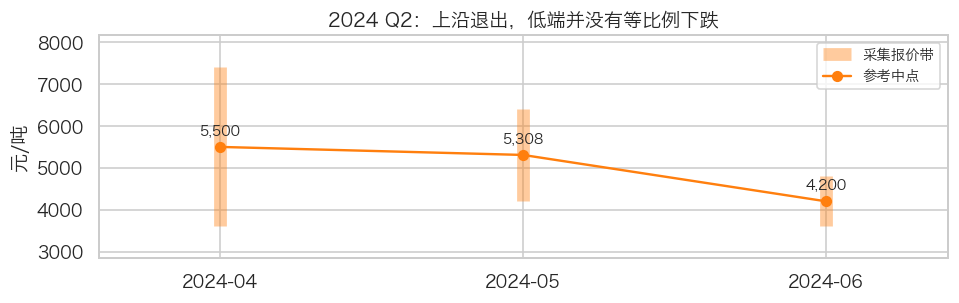

In [7]:
quarter_plot(qs, '2024Q2', '2024 Q2：上沿退出，低端并没有等比例下跌')

**对照数据再看：** 4月到6月参考中点5500→4200，下降23.6%；上沿7400→4800，下沿3600→3600。这个季度最明显的是高报价退下来了，不能把跌幅直接理解成所有厂家的成本一起下降。

**2024第三季度**
+ 价格在4500-5000每吨区间窄幅处理，横盘，需求淡季
  + 多地沿炼厂集中检修，由于亏损而集中检修
  + 七月锌锭进口量下降，但是七月过后进口窗口打开，回升到2.65万吨
  + 终端需求减弱

总结：
沿炼厂因亏损集体检修，加少了供应，而进口锌锭的流入弥补了供应缺口，但是终端进入淡季，压制了价格上行的空间，导致了锌价在高位震荡，并没有出现单边的行情



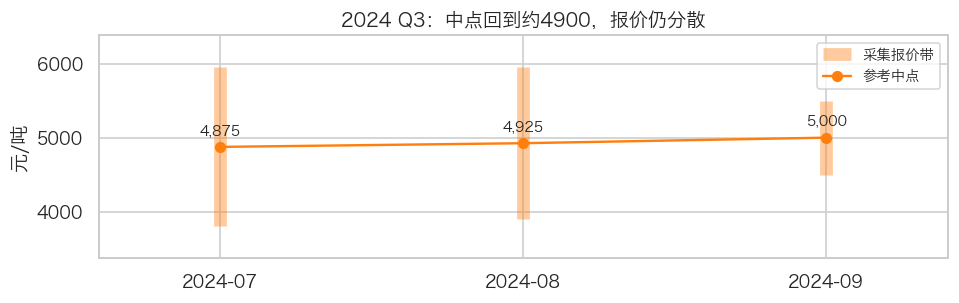

In [8]:
quarter_plot(qs, '2024Q3', '2024 Q3：中点回到约4900，报价仍分散')

**对照数据再看：** 7—9月中点4875、4925、5000，看起来横盘；三个月带宽分别2150、2050、1000。判断只看到了价格横住，原料出口分流和TC托底仍属于原有解释。

**2024第四季度**
+ 年末价格回升。10-11月份价格回升到5000-5500元每吨。最主要的原因是上游矿端紧张以及研练减产
    + 北方高海拔矿山因为天气转冷进入季节性停产
    + 加工费持续低位导致沿炼厂停产以及生产成本的增加
    + 沿炼厂的冬储集中启动，加剧了对国产矿产资源的争夺
    + 锌锭的社会库存降至历史最低位，极低的社会库存和社会高升水，让锌价综合上升
    + 镀锌开工率12月为百分之62.48， 氧化锌的开工率为百分之57.15，整体表现平淡，饲料级氧化锌订单有所提高，但是很有限



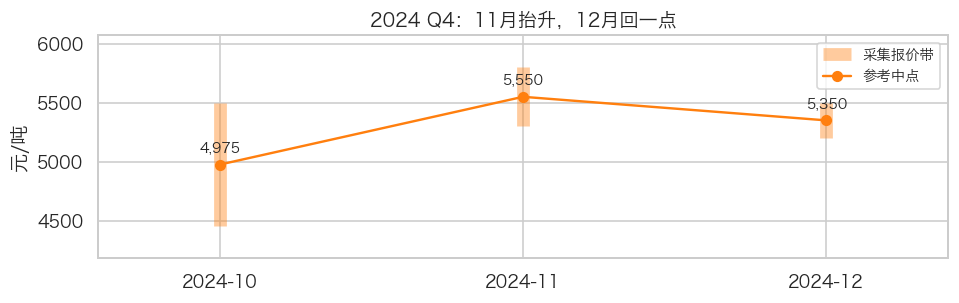

In [9]:
quarter_plot(qs, '2024Q4', '2024 Q4：11月抬升，12月回一点')

**对照数据再看：** 10—12月中点4975、5550、5350。上涨集中在11月，不能把季度概括成连续上涨；冬储和天气是否传到我们接触的厂家，还要看其原料库存和交期。

**2024总结**
2024年的必然规律

第一季度：
    
    正常启动，春节后下游化肥，饲料复产，需求释放，只要上游稳定，价格还是会有一波利空

第二季度到第三季度
    
    高温多雨，化肥进入淡季，饲料店家，每年的垃圾时间，需求端多空力气处于均衡状态，在没有额外因素的情况很难单边涨跌，大部分为低位横盘

第四季度
    
    北方因为天气停产，沿炼厂会开始抢矿冬储，成本端tc会被压低，下游为了春节而备货，所以价格不会跌到哪里去

2024年偶发事件

湖南/河南集中停产与次氧化锌断供（多）—— 价格飙升

    为什么会影响价格，因为需求端没有事情发生，旺季需求保持正常，但是供给端暴雷太大了，多头拔河赢了空头，多头买家拿钱都买不到货

宏观降息预期落空引发runs

    第一季度的大量涨幅积累了泼墨，当美联储降息落空，交易所资金撤离，锌价暴跌，同时化肥淡季导致需求端拉不来价格，所以价格跌回原来的水平线，这个时候空头拔河赢了因为他们拿钱跑了，也没多头看涨




这里原话里的“必然规律”先保留为判断。我们只有2024、2025两个完整年份，而且采价口径还换过，后面会用一水的跨年季度图再看：低点到底是不是每年落在同一季。

**2025年第一季度**

整个一年的价格压缩在了4800-5200元每吨的区间内，离散度还是很低的，说明是一场长距离拉扯战
+ 2025年锌精矿的加工费保持在3500的高位
+ 矿端目前没有什么压力
+ 硫酸的价格在持续稳步的上升
+ 硫酸锌的价格在4900附近徘徊

整体比较安静，没有什么大的变化，价格没有低到哪里去，上游和加工没有搞事情，该赚钱的赚钱，该供应的供应

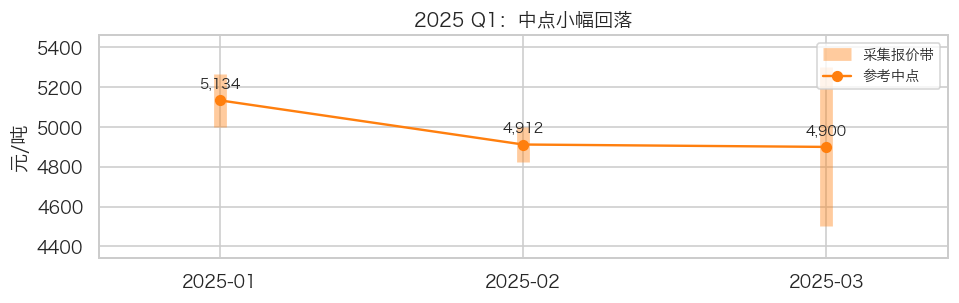

In [10]:
quarter_plot(qs, '2025Q1', '2025 Q1：中点小幅回落')

**对照数据再看：** 1—3月中点5134→4912→4900，季内首末下降4.6%。2月带有滚动统计，3月又是混规格市场报价，数字接近也不等于同一批货稳定成交。

**2025第二季度**

硫酸回调与磷肥淡季的短暂喘息
+ 硫酸的价格还在回调
+ 磷肥的需求比较的平淡，正常淡季
+ 锌矿的加工费增长放缓

总结：
价格横盘的原因在于三方都在发力， 成本端锌价跌幅温和，加工费高位持稳，硫酸也是高位震荡

需求端也由于是淡季需求疲软
一水硫酸锌的开工率在百分之八十五到百分之九十四的高位，七水硫酸锌的开工率也维持在了百分之九十左右，供应十分稳定，甚至供大于求


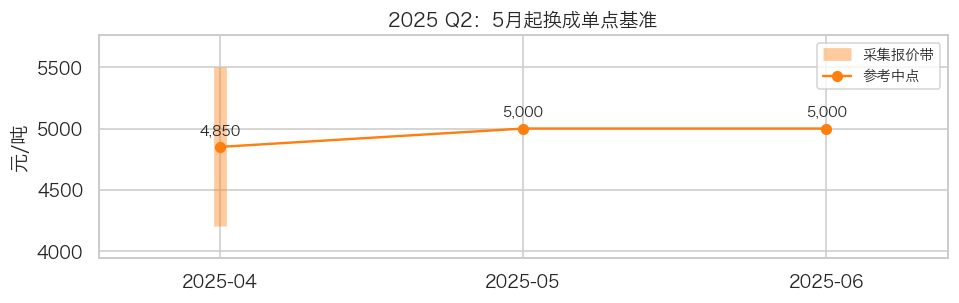

In [11]:
quarter_plot(qs, '2025Q2', '2025 Q2：5月起换成单点基准')

**对照数据再看：** 4月是4200—5500的混合报价，5—6月各只有5000这个基准点。图上收窄很大一部分来自采价方式改变，不能据此证明供应稳定、供大于求或者利润被挤压。

**2025第三季度**

这是2025年供给最动荡的一个季度，但是价格诡异的没有改变太大，甚至十分稳定，也只是小幅的震荡

+ 北方环保力度加大，天津，唐山钢厂限产，河内与河南部分次氧化锌厂停产，此氧化锌的的价格涨到了三年的最高位置
+ 硫酸锌价格并并没有受到太大的影响
+ 下游肥料需求缺乏增量

原因是由于需求很淡，如果上游涨价，下游在那个时候可以不买。所以如果没有这个事件，本来硫酸锌的价格会由于淡季而下降，由于需求带不起来，但是正好上游出了问题，这也就变相的拉高了硫酸锌的价格，这样两者对冲其实会让价格处于一个比较稳定的位置。 其次就是阅兵为一个比较短期的事情，所以大家普遍都觉得是短期性质的短缺，所以就不会出现大量囤货或者套利。因为持有硫酸锌的周期是比较短的

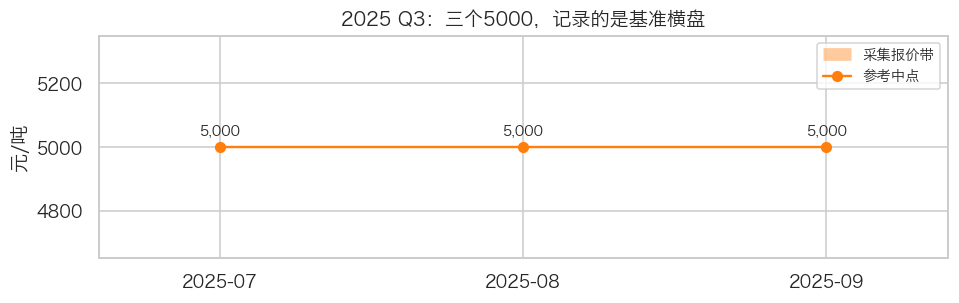

In [12]:
quarter_plot(qs, '2025Q3', '2025 Q3：三个5000，记录的是基准横盘')

**对照数据再看：** 7—9月记录都是5000，能确认的是这条基准没变。原话里“需求抵消了供给冲击”的解释可以留着，但单点价格没有厂家库存、原料成本和订单数据，无法验证两边刚好抵消。

**2025第四季度**

硫酸的价格还在稳步抬升，为2026年的疯狂埋下伏笔

+ 硫酸出厂价917元每吨
+ 锌矿tc持续下降，年末国产tc跌破1000元，但是也是有稀贵以及硫磺的价格给沿炼厂拖底
+ 硫酸锌的价格维持在4850-5000元每吨

上游不放货，下游一看价格高了又不买，沿炼厂要同时承担上游缩减的加工费，还要承担下游哪怕在旺季的对于价格的高明感度，利润空间被疯狂挤压，沿炼厂把价格要死在这个区间就是保住最后一点通过副产拿到的利润空间

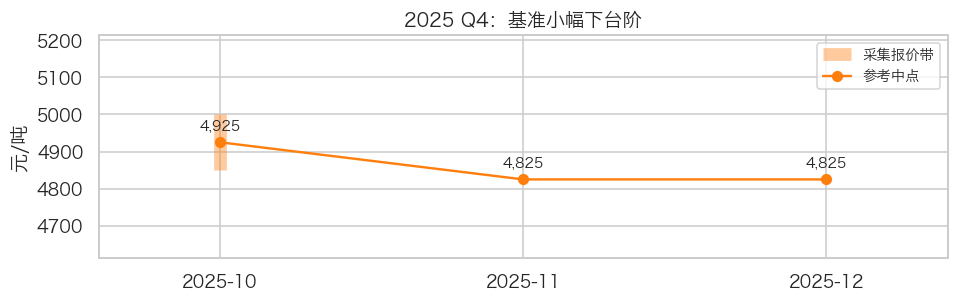

In [13]:
quarter_plot(qs, '2025Q4', '2025 Q4：基准小幅下台阶')

**对照数据再看：** 10—12月参考中点4925→4825→4825，首末下降2.0%。价格回落和利润收缩是两件事，这里能量出来的是前者，后者缺少工厂成本。

**2025年度总结**

2025年是一个及其无聊，但是又非常残酷的上游减产惯性从而导致中层利润空间被挤压死的一年。

价格方面：

    全年卡死在4800-5100元每吨的价格，这是三方权重相互抵消的一年，每当供给端想拉涨，就被极度平淡的需求扑灭的一年

成本：

    就像我刚刚说的，沿炼厂利润两头疯狂挤压

进出口：

    外强内弱，由于需求低迷，导致国内价格被压的很低，而国外需求稳定，这导致了外国的货进不来，国内卖不上价格进来就亏钱，因为需求低迷

出口额增长能说明金额增加，不能单独证明“外强内弱”或者国外需求稳定。出口部分放在后面用离散数据单独看。

**2026年第一季度**

+ 锌矿tc跌倒五百元每吨左右
+ 硫酸价格上涨破一千每吨
+ 硫磺均价同比上涨百分之一百三左右
+ 开工率百分之八十，产能利用率百分之六十五，供应有所提升，但是成本端的利润还是在被挤压




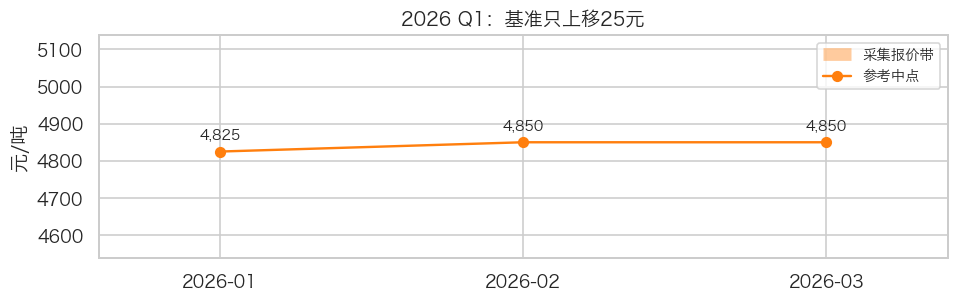

In [14]:
quarter_plot(qs, '2026Q1', '2026 Q1：基准只上移25元')

**对照数据再看：** 1—3月4825→4850→4850，首末上升0.5%。原文提到硫酸、硫磺和TC明显变化，但这张表没有显示硫酸锌同步大涨，不能把上游新闻直接等比例代入成品报价。

### 2026年Q2—Q4

Q2七水4、5月在4850、4825，6月变成5125，涨幅集中在6月。Q3三个点都是5125。Q4只有10月和11月采价片段，10月混入4500—5800的厂家报价，11月又回到5125单点，所以先不把两个月中点的小变化解释成供需转向。

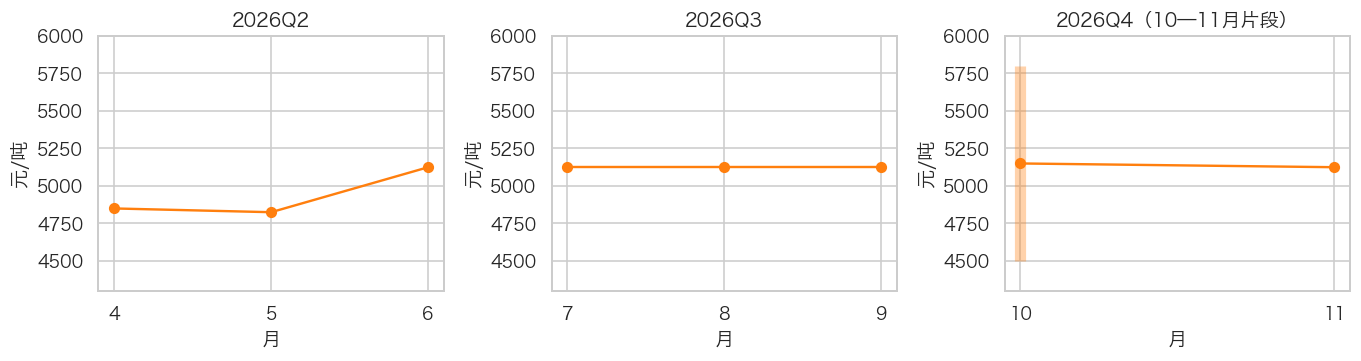

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
for ax, p in zip(axes, ["2026Q2", "2026Q3", "2026Q4"]):
    s = qs.loc[qs["季度"].eq(p)]
    ax.vlines(s["月"], s["最低价"], s["最高价"], color="tab:orange", lw=7, alpha=.35)
    ax.plot(s["月"], s["参考中点"], "o-", color="tab:orange")
    ax.set(title=p + ("（10—11月片段）" if p.endswith("4") else ""), xticks=s["月"], xlabel="月", ylabel="元/吨", ylim=(4300, 6000))
plt.tight_layout()
plt.show()

## 样本分析（一水）

### 先看基本稳定盘到底在哪里

一水这里我更关心的是：低报价有没有真的抬起来，高报价有没有卖下去，以及中间这个数是不是因为换了一批报价才变了。

先看三个年份，2024年中点主要围着7250转；2025年中位数降到6475；2026年已有11个月中位数6350。2024与2025是全年，2026只到11月片段，先分开摆。四分位带只是月度中点中间一半所在的位置，不能当作采购底价。

,月份数,中点中位数,中点25分位,中点75分位,中点最低,中点最高,平均报价带宽
年,,,,,,,
2024,12,7250.0,7112.5,7275.0,6700.0,7850.0,1858.3
2025,12,6475.0,6100.0,6800.0,5350.0,7350.0,2500.0
2026,11,6350.0,6000.0,6800.0,5550.0,6950.0,3027.3


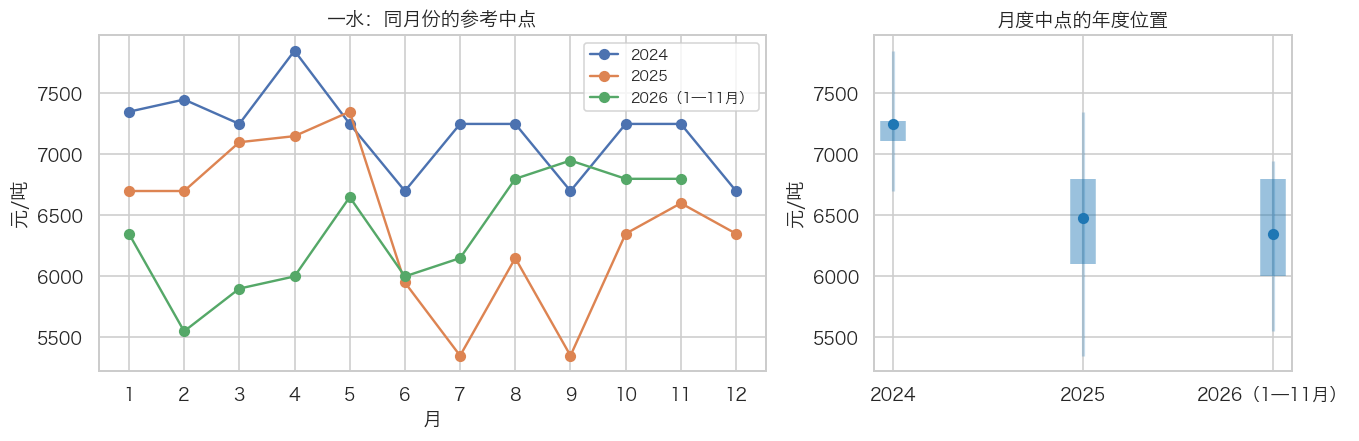

In [16]:
annual = ys.groupby("年").agg(
    月份数=("参考中点", "size"), 中点中位数=("参考中点", "median"),
    中点25分位=("参考中点", lambda s: s.quantile(.25)),
    中点75分位=("参考中点", lambda s: s.quantile(.75)),
    中点最低=("参考中点", "min"), 中点最高=("参考中点", "max"),
    平均报价带宽=("报价带宽", "mean"))
display(annual.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.6, 1]})
for year, s in ys.groupby("年"):
    axes[0].plot(s["月"], s["参考中点"], marker="o", label=str(year) + ("（1—11月）" if year == 2026 else ""))
axes[0].set(title="一水：同月份的参考中点", xlabel="月", ylabel="元/吨", xticks=range(1, 13))
axes[0].legend(fontsize=9)
for pos, (year, row) in enumerate(annual.iterrows()):
    axes[1].vlines(pos, row["中点最低"], row["中点最高"], color="tab:blue", alpha=.25, lw=2)
    axes[1].vlines(pos, row["中点25分位"], row["中点75分位"], color="tab:blue", alpha=.45, lw=16)
    axes[1].scatter(pos, row["中点中位数"], color="tab:blue", zorder=3)
axes[1].set(title="月度中点的年度位置", ylabel="元/吨", xticks=range(len(annual)), xticklabels=["2024", "2025", "2026（1—11月）"])
plt.tight_layout()
plt.show()

In [17]:
def mono_quarter_grid(year):
    fig, axes = plt.subplots(1, 4, figsize=(13, 3.25), sharey=True)
    for q, ax in enumerate(axes, start=1):
        s = ys.loc[ys["年"].eq(year) & ys["日期"].dt.quarter.eq(q)]
        ax.vlines(s["月"], s["最低价"], s["最高价"], color="tab:blue", alpha=.3, lw=8)
        ax.plot(s["月"], s["参考中点"], "o-", color="tab:blue")
        for m, v in zip(s["月"], s["参考中点"]):
            ax.annotate(f"{v:.0f}", (m, v), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8)
        ax.set(title=f"Q{q}" + ("（10—11月片段）" if year == 2026 and q == 4 else ""),
               xticks=s["月"], xlabel="月", ylim=(3600, 9400))
    axes[0].set_ylabel("元/吨")
    fig.suptitle(f"{year}年一水：每季中点和报价上下沿", y=1.02, fontsize=13)
    plt.tight_layout()
    plt.show()

### 2024年一水：没有七水那么夸张，主要看4月之后怎么退下来

**第一季度：** 中点7350、7450、7250，季内首末下降1.4%。七水同期往上走，一水没有跟着一起拉升，所以不能把七水的故事直接搬过来。

**第二季度：** 4月7850是全年中点高点，5月7250，6月6700。4—6月下降14.6%，低价端7500→5200，高价端一直在8200附近。多空拔河的结果更像是低价货重新出来了，高挂牌还挂在那里。

**第三季度：** 7、8月中点7250，9月6700。9月主要是低端5200重新进入样本，高端反而仍有8200。这个季度不适合直接写成“厂家一起降价”，得先问低价那批货的规格和交付条件。

**第四季度：** 10、11月7250，12月6700，和Q3中点的节奏相似。两季都出现5200的低端报价，但还是挂牌样本；它能给询价一个线索，不能凭这个就说年底必然有便宜货。

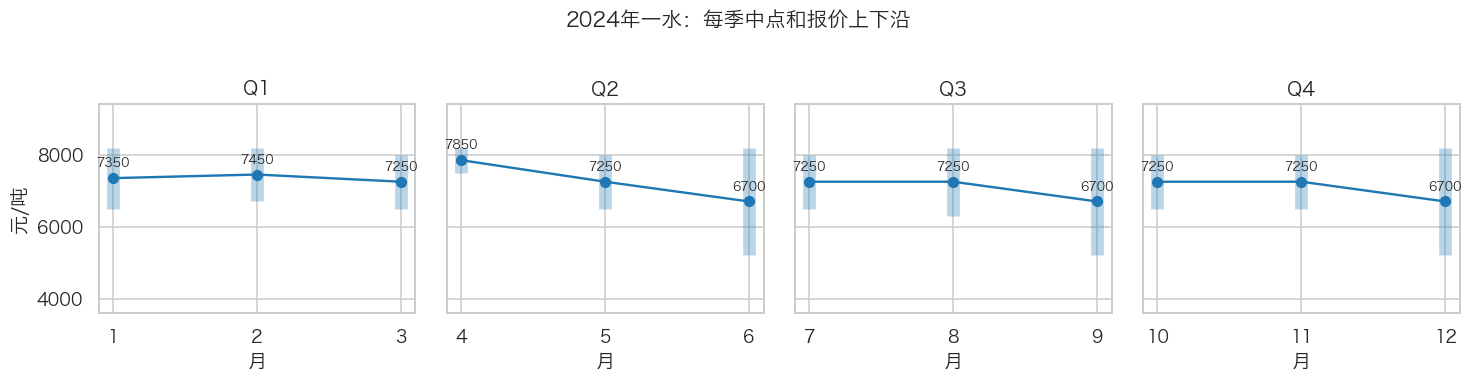

In [18]:
mono_quarter_grid(2024)

### 2025年一水：七水横盘的时候，一水已经换了价格台阶

**第一季度：** 1、2月中点6700，3月7100，季内首末上涨6.0%。3月的区间由5200—8200变成6500—7700，低端抬升、高端下降，更多是报价组合在变化，不能只看中点说成本普涨。

**第二季度：** 4月7150、5月7350、6月5950。5—6月中点下降19.0%，低端6500→4200，高端8200→7700。这里是最值得拿去问供应商的一段：同样写35.5%的富盛永出现4200，为什么其他报价还在6500以上？表里还没有答案，不能先替厂家填成亏损甩货。

**第三季度：** 7、9月中点5350，8月6150，季度中点均值5617，是这三年完整季度里最低的一季。但是8月注明规格混杂，6150这一下不能自动解释成旺季反弹。要看的是低价端有没有持续抬起来；7、9月都还有4200。

**第四季度：** 中点6350、6600、6350，看上去比Q3回升。问题是11月只有湖南锐启农业级颗粒阶梯价6400—6800，10月和12月却是4200—8500的混合规格。11月变窄主要是样本换了，先不要往供需稳定上解释。

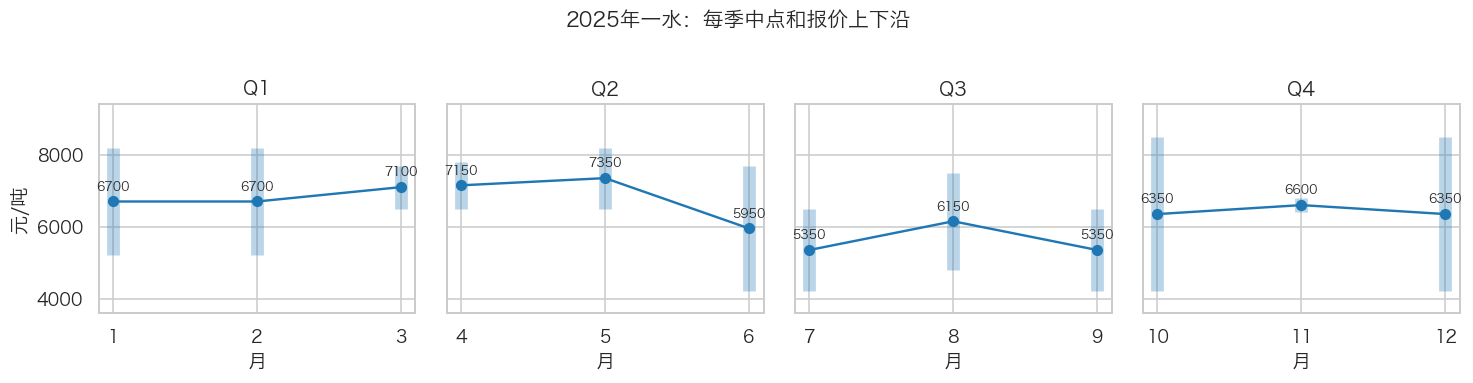

In [19]:
mono_quarter_grid(2025)

### 2026年一水：中点回升，但先拆开上沿、下沿和样本

**第一季度：** 6350、5550、5900，2月最低。1—2月低端都是4200，主要是高端8500降到6900；这次下移和2025年6月的低端下移不是同一种结构。

**第二季度：** 6000、6650、6000，低端三个月都是4800，5月高端升到8500后又退回7200。这里我不会直接说需求带起了价格，因为中点变化主要发生在高端样本。

**第三季度：** 6150、6800、6950，看上去连续上涨。但8月4800—8800，9月6500—7400，9月备注里没有富盛永低报价和佳业高报价。涨到6950的时候，首先要确认两端报价是真的撤了，还是这个月没有采到。

**第四季度（只看10—11月片段）：** 中点都在6800，区间也都是4800—8800。9月的窄区间没有延续，10月两端重新出现。11月也还没有走完，所以这里只能说目前采到的报价结构重复了，不能下全年结论。

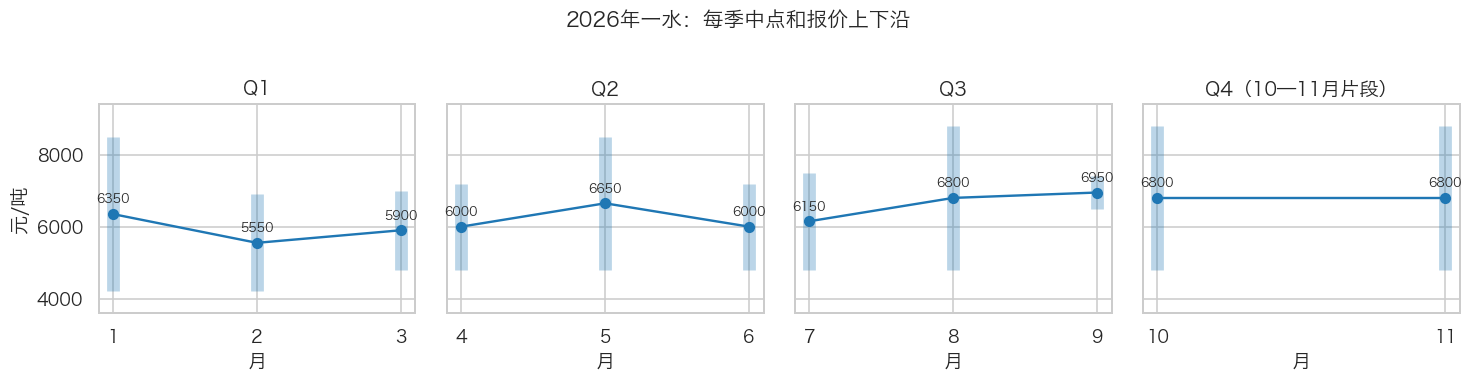

In [20]:
mono_quarter_grid(2026)

### 变化拆分

我现在更愿意先问“是哪一边动了”。同样是中点下降，2025年6月主要是低端掉下来，2026年2月主要是高端退下来。2026年9月中点还涨了一点，但两边往中间收，背后又有报价样本缺席。这三件事拿去和工厂谈，问题完全不一样。

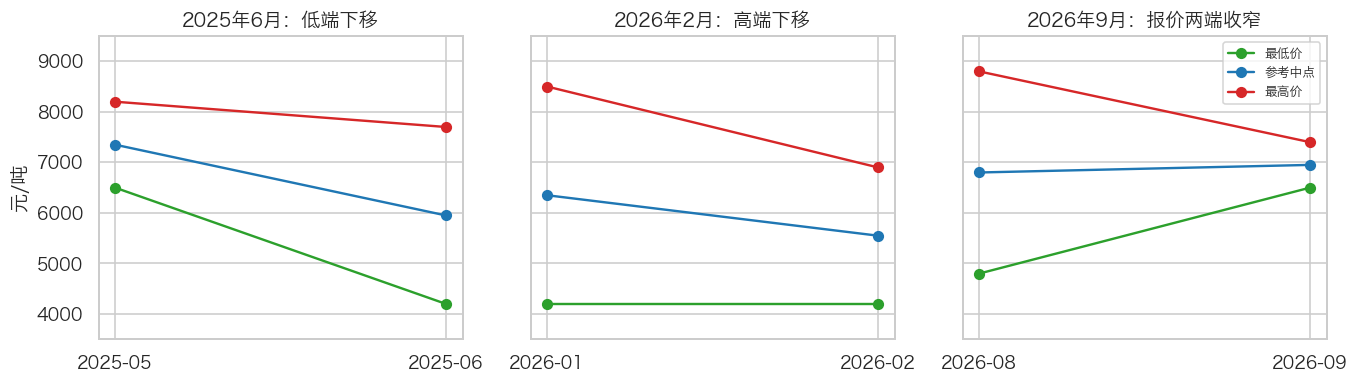

,变化,低端变化,高端变化,中点变化%
0,2025-05→2025-06,-2300.0,-500.0,-19.05
1,2026-01→2026-02,0.0,-1600.0,-12.60
2,2026-08→2026-09,1700.0,-1400.0,2.21


In [21]:
events = [("2025-05", "2025-06", "2025年6月：低端下移"),
          ("2026-01", "2026-02", "2026年2月：高端下移"),
          ("2026-08", "2026-09", "2026年9月：报价两端收窄")]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
indexed = ys.set_index("时间")
event_rows = []
for ax, (before, after, title) in zip(axes, events):
    s = indexed.loc[[before, after]]
    for col, color in [("最低价", "tab:green"), ("参考中点", "tab:blue"), ("最高价", "tab:red")]:
        ax.plot([0, 1], s[col], "o-", label=col, color=color)
    ax.set(title=title, xticks=[0, 1], xticklabels=[before, after], ylim=(3500, 9500))
    event_rows.append({"变化": before + "→" + after,
                       "低端变化": s["最低价"].iloc[1] - s["最低价"].iloc[0],
                       "高端变化": s["最高价"].iloc[1] - s["最高价"].iloc[0],
                       "中点变化%": (s["参考中点"].iloc[1] / s["参考中点"].iloc[0] - 1) * 100})
axes[0].set_ylabel("元/吨")
axes[-1].legend(fontsize=8)
plt.tight_layout()
plt.show()
display(pd.DataFrame(event_rows).round(2))

### 所谓每年的稳定盘，有没有固定季节

如果规律真的是“二三季度便宜、四季度贵”，至少得在不同年份看到差不多的形状。这里2024、2025的Q3均值都低于Q1，但2026已有数据却是Q1低、Q3高。2024的Q3和Q4还完全相同。

所以我会把“淡季可能更好谈价”保留成观察方向，不写成每年必然能买到低价。尤其2025年Q4换样本、2026年Q4缺月份，不能拿这两个格子强行总结季节规律。

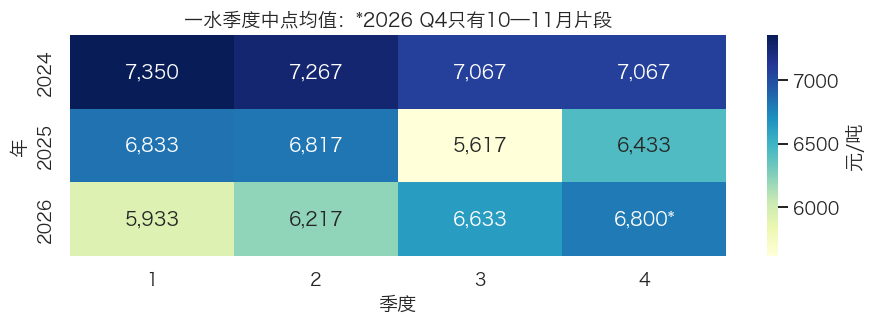

月份数  季内中点均值    首月中点    末月中点  平均报价带宽  季内首末变化%
年    季度                                                  
2024 2024Q1    3  7350.0  7350.0  7250.0  1566.7     -1.4
     2024Q2    3  7266.7  7850.0  6700.0  1733.3    -14.6
     2024Q3    3  7066.7  7250.0  6700.0  2133.3     -7.6
     2024Q4    3  7066.7  7250.0  6700.0  2000.0     -7.6
2025 2025Q1    3  6833.3  6700.0  7100.0  2400.0      6.0
     2025Q2    3  6816.7  7150.0  5950.0  2166.7    -16.8
     2025Q3    3  5616.7  5350.0  5350.0  2433.3      0.0
     2025Q4    3  6433.3  6350.0  6350.0  3000.0      0.0
2026 2026Q1    3  5933.3  6350.0  5900.0  3066.7     -7.1
     2026Q2    3  6216.7  6000.0  6000.0  2833.3      0.0
     2026Q3    3  6633.3  6150.0  6950.0  2533.3     13.0
     2026Q4    2  6800.0  6800.0  6800.0  4000.0      0.0

In [22]:
yq = quarter_stats(ys)
season = yq.reset_index()
season["季"] = season["季度"].str[-1].astype(int)
piv = season.pivot(index="年", columns="季", values="季内中点均值")
labels = piv.map(lambda v: f"{v:,.0f}") if hasattr(piv, "map") else piv.applymap(lambda v: f"{v:,.0f}")
labels.loc[2026, 4] += "*"
fig, ax = plt.subplots(figsize=(8, 3))
sns.heatmap(piv, annot=labels, fmt="", cmap="YlGnBu", ax=ax, cbar_kws={"label": "元/吨"})
ax.set(title="一水季度中点均值：*2026 Q4只有10—11月片段", xlabel="季度", ylabel="年")
plt.tight_layout()
plt.show()
display(yq.round(1))

### 6500这个锚点，能不能拿来用

原表35个有值月份里，20个月的备注出现6500。它经常对应凯捷或天悦的挂牌，2025年6月的中点已经降到5950，备注里仍然有6500，这说明一个长期挂牌并不自动跟着市场中点走。

这个锚点可以用来找同一家厂家重新问价：现在是不是还报6500，什么规格，是否含税含运，多久交货。不能拿“出现次数多”推成成交最多，也不能说6500就是成本底。备注没写到某厂家，只表示这张采价表没记录到，不能说它没货。

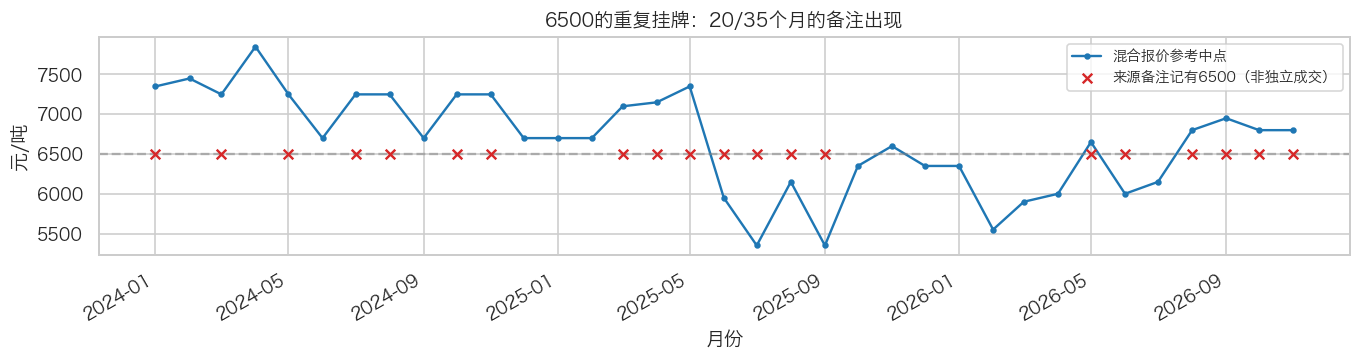

In [23]:
ys["备注含6500"] = ys["来源备注"].str.contains(r"(?<!\d)6500(?!\d)", regex=True)
fig, ax = plt.subplots(figsize=(12, 3.3))
ax.plot(ys["日期"], ys["参考中点"], color="tab:blue", marker="o", ms=3, label="混合报价参考中点")
anchor = ys.loc[ys["备注含6500"]]
ax.scatter(anchor["日期"], np.full(len(anchor), 6500), marker="x", color="tab:red", label="来源备注记有6500（非独立成交）", zorder=4)
ax.axhline(6500, color="gray", linestyle="--", alpha=.5)
ax.set(title=f"6500的重复挂牌：{len(anchor)}/{len(ys)}个月的备注出现", ylabel="元/吨", xlabel="月份")
ax.legend(fontsize=9)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### 一水和七水放在一起看，先把比较口径摆平

2025年七水中点大体横着走，一水6月以后却明显下了台阶。两个产品没有同步，所以七水的平稳不能代替一水的采购判断。

如果只按产品吨比，一水当然更贵；按原表名义含锌量一水35%、七水21.5%换算成每公斤锌，一水这组报价反而大部分月份更低。但这还是混合挂牌和基准之间的量级对照，等级、重金属、粒度、含水和交付条款都没有统一，不能据此算利润、做套利，或者认为两个品种可以直接替代。

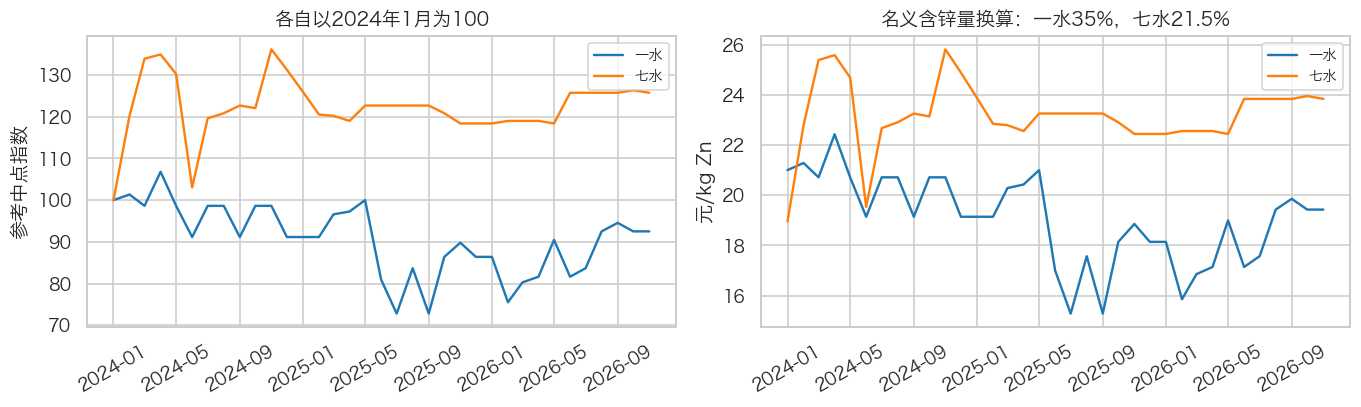

In [24]:
pair = ys[["时间", "日期", "参考中点"]].merge(
    qs[["时间", "参考中点"]], on="时间", suffixes=("_一水", "_七水"), validate="one_to_one")
pair["一水元每公斤锌"] = pair["参考中点_一水"] / (1000 * .35)
pair["七水元每公斤锌"] = pair["参考中点_七水"] / (1000 * .215)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.7))
for suffix, color in [("一水", "tab:blue"), ("七水", "tab:orange")]:
    series = pair["参考中点_" + suffix]
    axes[0].plot(pair["日期"], series / series.iloc[0] * 100, label=suffix, color=color)
    axes[1].plot(pair["日期"], pair[suffix + "元每公斤锌"], label=suffix, color=color)
axes[0].set(title="各自以2024年1月为100", ylabel="参考中点指数")
axes[1].set(title="名义含锌量换算：一水35%，七水21.5%", ylabel="元/kg Zn")
for ax in axes:
    ax.legend(fontsize=9)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

## 研究方向转到我们接触的厂家

### 原料是含锌固废，成本就要沿着这条路线往下拆

按照我们接触的供应商情况，我想把重点放在含锌固废的进厂、回收和出货上。这里“钢厂废渣”还要问具体是什么：钢厂除尘灰、其他含锌尘泥和普通钢渣不能自动当成同一种原料。

这条方向有实际工艺案例。埃索凯公开的环境资料写的是电炉除尘灰、铁合金除尘灰、铁矾渣等含锌原料，经回转窑制成次氧化锌，再漂洗、硫酸反应、提纯生产一水硫酸锌。所以废料路线里仍可能有次氧化锌这个中间环节，也要分清厂家自己回收，还是外购中间品。[公司环境公示，第一、二节](https://www.iskychem.cn/tongzhigonggao/69.html)

原料变了，锌价也不能直接扔掉。公司招股书仍把次氧化锌、含锌固废采购价格与金属锌价格联系起来。更实用的问法是：这家厂家这批原料按什么系数计价，什么时候重定价，库存能用多久；TC保留在背景里，不直接当成硫酸锌厂的加工费。[招股书，第1-1-28页](https://reportdocs.static.szse.cn/UpFiles/rasinfodisc1/202302/RAS_202302_47CE99AF34EF4439A109BEB705861DEB.pdf#page=28)

### 权重放在哪里，先看每吨合格品实际要花什么

这里我会把原来的“权重”问题改成一条更具体的成本路线。下面是分析框架，不是已经测出来的厂家成本。

$$
每吨合格品净成本 = 含锌原料成本 + 酸耗 + 能源 + 回收净化加工 + 残渣处置 + 包装运输 - 副产品净收益
$$

如果原料按湿吨进厂，先设干基含锌品位为 $z$、含水率为 $m$、锌总回收率为 $r$、成品含锌比例为 $w$，那么：

$$
每吨成品需要的湿原料吨数 = \frac{w}{(1-m)zr}
$$

原料成本就是这个用量乘以每湿吨原料的到厂价或净结算成本。这里已经能看出来，同样报一吨原料的价格，品位、含水和回收率不同，做出一吨合格品的成本就不同。原料若按干吨或锌金属量结算，要先统一口径，不能直接往这个式子里塞。

除杂也不是只有收益。埃索凯工艺披露有副产金属、盐类和余热利用，同时环境公示也列有浸出渣、铋渣委外处置。我的理解是要看“副产品卖出去后、扣完回收和处置的净收益”，不能把所有杂质都默认算成利润。这是公司实例，不能代替我们每家供应商的账。[招股书，第1-1-100至101页](https://reportdocs.static.szse.cn/UpFiles/rasinfodisc1/202302/RAS_202302_47CE99AF34EF4439A109BEB705861DEB.pdf#page=100)、[环境公示，第三节](https://www.iskychem.cn/tongzhigonggao/69.html)

所以多空拔河的时候，我更想先问下面这些，再判断哪个因素真的有分量：

| 看到的变化 | 我想核对什么 | 对报价的判断怎么落下来 |
| --- | --- | --- |
| 厂家说原料紧了 | 具体原料类别、实际到厂量、库存能用几天、是否切换原料 | 同规格低报价持续抬升、交期也拉长，才更接近可交付货变紧 |
| 原料吨价看上去很便宜 | 干基锌品位、含水、回收率及计价方式 | 比每吨合格品的原料成本，不能只比每吨废料 |
| 厂家说酸和加工都涨了 | 每吨合格品酸耗、酸的到厂价、能源和净化费用 | 费用变化乘实际单耗，不能把酸的涨幅直接当成硫酸锌涨幅 |
| 厂家说杂质都能卖 | 已实现的副产品收入，以及回收、精制和残渣处置费用 | 看净收益能抵多少，别把潜在回收价值当现金收入 |
| 市场中点没涨 | 同规格成交条件、订单、成品库存和交期有没有变化 | 可能是成本没涨，也可能是涨了卖不动，价格表拆不开这两种情况 |

现有附件没有这些成本和运营变量，所以这里不填假权重、不估厂商利润。先用价格图找到要问的那一段，再拿同一家、同规格、同条款的报价去验证。

## 出口与国际参考，单独放在这里看

出口这张表是零散点，2023全年和几个单月不能连成一条连续月度趋势。统一成美元/吨以后，2025年10月是882，2026年9月935.1，后者高6.0%，只能说这两个观察点有差别，不能说连续上涨。

2024到2025出口额增长29.2%，还分不清数量、单价和规格组合各贡献多少。2026年7到8月出口量反而下降13.2%。这几条证据不能拼成“外国需求一直强”。国内挂牌、FOB平台挂牌和海关综合均价也有税运、规格和时期差异，不能直接相减算出口利润。

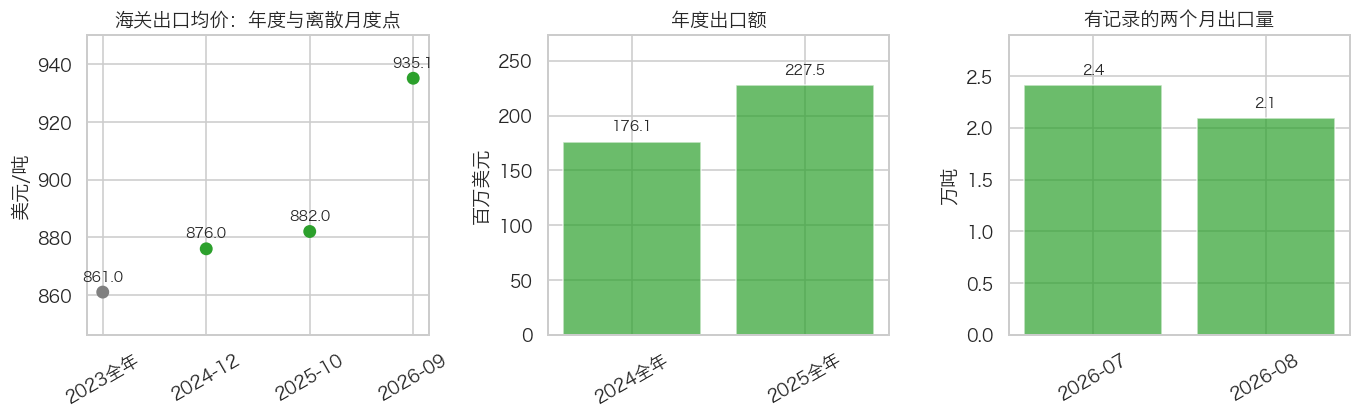

2024→2025出口额变化：+29.18%
2026年7→8月出口量变化：-13.16%


In [25]:
# 三类指标各用自己的单位；年度点和月度点分开画，不补缺失月份。
export_prices = exp.loc[exp["项目"].str.contains("出口均价")].copy()
export_prices["美元每吨"] = pd.to_numeric(export_prices["价格"], errors="raise") * 1000
export_values = exp.loc[exp["项目"].str.contains("出口额")].copy()
export_values["百万美元"] = pd.to_numeric(export_values["价格"].str.replace(",", "", regex=False)) / 1e6
export_qty = exp.loc[exp["项目"].eq("中国海关出口量")].copy()
export_qty["万吨"] = pd.to_numeric(export_qty["价格"].str.replace(",", "", regex=False)) / 1e7

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for n, (ax, s, col, title, unit) in enumerate([
    (axes[0], export_prices, "美元每吨", "海关出口均价：年度与离散月度点", "美元/吨"),
    (axes[1], export_values, "百万美元", "年度出口额", "百万美元"),
    (axes[2], export_qty, "万吨", "有记录的两个月出口量", "万吨")]):
    x = np.arange(len(s))
    if n == 0:
        colors = ["gray" if "全年" in t else "tab:green" for t in s["时间"]]
        ax.scatter(x, s[col], c=colors, s=50)
    else:
        ax.bar(x, s[col], color="tab:green", alpha=.7)
    for xi, v in zip(x, s[col]):
        ax.annotate(f"{v:.1f}", (xi, v), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=9)
    ax.set(title=title, ylabel=unit, xticks=x, xticklabels=s["时间"])
    ax.tick_params(axis="x", rotation=30)
    ax.margins(y=.2)
plt.tight_layout()
plt.show()

value_growth = (export_values["百万美元"].iloc[1] / export_values["百万美元"].iloc[0] - 1) * 100
qty_change = (export_qty["万吨"].iloc[1] / export_qty["万吨"].iloc[0] - 1) * 100
print(f"2024→2025出口额变化：{value_growth:+.2f}%")
print(f"2026年7→8月出口量变化：{qty_change:+.2f}%")

### 同样叫FOB，一水的不同等级也要分开

农业级一水400—500美元/吨，饲料级一水950—1200，表面价差很大。但原表只写“近期”，没有完整条款和统一采价时间。这张图只负责提醒我先分等级，不能拿低档挂牌去压另一种等级的供应商，更不能把平台最低价当成真实可成交底价。

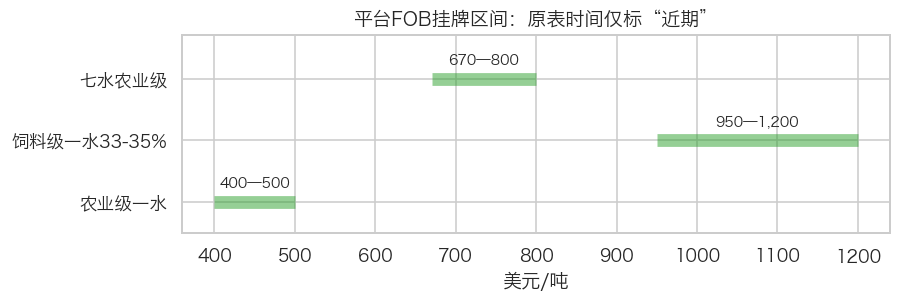

In [26]:
fob = exp.loc[exp["项目"].str.startswith("中国FOB挂牌")].copy()
fob[["低", "高"]] = fob["价格"].apply(
    lambda s: pd.Series([float(v.replace(",", "")) for v in re.split(r"[–—-]", s)]))
fob["标签"] = fob["项目"].str.replace("中国FOB挂牌 · ", "", regex=False)
fig, ax = plt.subplots(figsize=(8, 2.8))
for y, (_, row) in enumerate(fob.iterrows()):
    ax.hlines(y, row["低"], row["高"], color="tab:green", linewidth=8, alpha=.5)
    ax.annotate(f'{row["低"]:,.0f}—{row["高"]:,.0f}', ((row["低"]+row["高"])/2, y),
                xytext=(0, 9), textcoords="offset points", ha="center", fontsize=9)
ax.set(yticks=range(len(fob)), yticklabels=fob["标签"], xlabel="美元/吨", title="平台FOB挂牌区间：原表时间仅标“近期”", ylim=(-.5, len(fob)-.3))
plt.tight_layout()
plt.show()

## 回到这次最想判断的事情

一水的基本盘更适合分成两层：中点在哪个台阶，低端和高端分别是什么货。2025年6月低端下移、2026年2月高端退下来、2026年9月样本收窄，已经说明只看一条平均线会把不同事情混在一起。

对于我们接触的含锌固废路线厂家，接下来最有用的不是继续把矿山新闻堆上去，而是看同规格可交付报价是否持续变动，再问这批货的原料结算、品位、回收、净化、酸耗和副产品净收益。多空谁更有力，最后要落到“这批合格货做出来多少成本、能不能按时拿到、下游愿不愿意买”上面。

## 附录：原AI总结（原文保留）

下面是原稿中重复解释较多的四段，移到这里保留。它们属于原稿观点，不因为放进报告就变成已验证的事实或采购指令。

### 2024年第1季度原AI总结

AI总结：

2024年1月的矿端收紧，是通过“TC暴跌→锌价获得成本支撑→硫酸锌的锌原料成本抬升”这一链条传导的。当时LME锌价因供给担忧一度涨至2558.5美元/吨的两周新高。这正是我们之前分析的2024年Q1硫酸锌价格能从4100元/吨附近启动、并在3月加速拉升至5480元/吨以上的底层成本驱动力之一。后续值得持续跟踪的信号是：海外高成本矿山的减停产是否会形成趋势，以及国内高寒矿山在春季后的复产节奏，这两者将决定TC是继续下探还是迎来阶段性拐点。

### 2024年第2季度原AI总结

AI总结：

2024年Q2硫酸锌市场经历了一场经典的“戴维斯双杀”，价格从6400元/吨的巅峰急速崩塌至4200元/吨的谷底。Q1的“停产缺货”故事在Q2彻底失效，因为宏观降息预期落空导致锌价高位跳水（成本地基塌陷），叠加春肥结束和饲料疲软带来的需求真空，以及硫酸价格因化肥淡季出现的断崖式暴跌；这告诉采购新手：当成本端（锌与硫酸）出现高位回调松动且下游进入淡季时，任何供给端的停产利好都是掩护厂家逃跑的烟雾弹，此时绝不能高位接盘，最优策略是极限压低库存、随用随买，熬到月底厂家为了冲业绩自然会给出底价。

### 2024年第3季度原AI总结

AI总结：

供应端：国内“被动急刹车”撞上进口“先缺后补”。 7月锌精矿TC被压至极低位（进口TC甚至为负），冶炼厂亏损严重，被迫集中检修并联合减产，导致国内供应大幅收缩。但戏剧性的是，7月因前期比价亏损，进口锌锭也骤降至1.8万吨，国内减产与进口缺席叠加，让7月成为全年供应最紧的窗口。直到8-9月沪伦比价修复，进口量才激增至5.28万吨，勉强补上了国内的缺口。

需求端：淡季真空，缺乏承接力。 高温多雨天气加上传统消费淡季，下游饲料、化肥、镀锌等开工率低迷，仅维持刚需采购。需求端根本无力消化涨价，形成“旺季不旺”的僵局。

价格底牌：内外溢价与成本托底。 国内价格之所以跌不下去，是因为原料端（次氧化锌）受海外高溢价吸引出现出口分流，加剧了国内原料紧缺；同时，极低的TC意味着成本底座极其坚硬，厂家宁愿减产也不愿降价亏本甩卖。

### 2024年第4季度原AI总结

AI总结：

2024年Q4锌价（及硫酸锌成本底座）的回升，是一条清晰的供给驱动路径：矿山季节性停产 + 冬储抢矿 → TC极低 → 冶炼厂亏损减产 → 锌锭产量低位 + 库存去化至历史低位 → 价格获得刚性支撑。需求端在Q4的表现是“淡季不淡”的刚性维持，而非“旺季爆发”的增量拉动。因此，不能把当时的价格上涨简单归因于“旺季到了”，其可持续性取决于矿端紧张和冶炼亏损的格局何时被打破。

### 原图注的位置

原“右上图”标题按原文保留在2024年Q1段落。现在已把季度图放回各季度旁边，不再沿用原来的四宫格排版。原图中的hist/KDE也不再重复：混规格报价中点不是成交分布，画成概率密度容易让人读过头。

### 数据快照

三份CSV原文已保存在前面的代码里；下面列的是收到附件时的文件摘要，方便以后识别版本。它们记录的是原采集表的来源描述，不代表已经逐条核验了原始网络报价。新增工艺分析只引用正文标出的公司公示和招股书。

In [27]:
display(来源清单)

,文件,SHA256
0,一水硫酸锌_月度区间.csv,20c062e90fccb606754bcdb84711e7ac594ea4544288b4...
1,七水硫酸锌_月度区间.csv,42619d49b2507e6baa5828475a3afd52a427a876ca604e...
2,硫酸锌_出口与国际参考.csv,006b2b903f7131fc0cf53a874a1860c5e228e73496916a...
3,硫酸锌_月度价格区间_2024-2026.xlsx,2b91fa40f6b65bcbc3610ec032fc89070b3fc21a9e6e14...
4,zinc sulfate 3 years analysis.ipynb,df4c6604f61856c6cac55c1e8a38748a330fd11f4dc775...
